In [1]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import BaggingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.datasets import fetch_california_housing
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor

RANDOM_STATE = 42   # one seed for everything, so results are reproducible
results = {}        # model name -> dict of train/test metrics, filled in as we go

## 1. Data:

The features are on very different scales (for example `Population` is in the thousands and `AveBedrms` is around 1),
which matters for distance-based models such as KNN. Scaling is handled inside the KNN baseline below.

In [2]:
data = fetch_california_housing(as_frame=True)
X, y = data.data, data.target
print(f"X: {X.shape}   y: {y.shape}   (target: {y.name}, in $100,000)")
X.head()

X: (20640, 8)   y: (20640,)   (target: MedHouseVal, in $100,000)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25


In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print(f"train: {X_train.shape}   test: {X_test.shape}")

train: (16512, 8)   test: (4128, 8)


A small helper keeps every experiment to the same recipe: fit (optional), score on both the training and the test set, and record the metrics for the comparison at the end.
A large gap between train and test R² signals overfitting.

In [4]:
def evaluate(name, model, fit=True):
    if fit:
        model.fit(X_train, y_train)
    pred = model.predict(X_test)
    results[name] = {
        "train R2": model.score(X_train, y_train),
        "test R2": r2_score(y_test, pred),
        "test RMSE": np.sqrt(mean_squared_error(y_test, pred)),
    }
    r = results[name]
    print(f"{name}: train R2 = {r['train R2']:.3f} | test R2 = {r['test R2']:.3f} | test RMSE = {r['test RMSE']:.2f}")
    return model

## 2. Baselines:

In [5]:
lr = evaluate("Linear regression (single)", LinearRegression())
dt = evaluate("Decision tree (single)", DecisionTreeRegressor(random_state=RANDOM_STATE))
knn = evaluate("KNN (single)", make_pipeline(StandardScaler(), KNeighborsRegressor()))

Linear regression (single): train R2 = 0.613 | test R2 = 0.576 | test RMSE = 0.75
Decision tree (single): train R2 = 1.000 | test R2 = 0.623 | test RMSE = 0.70
KNN (single): train R2 = 0.797 | test R2 = 0.670 | test RMSE = 0.66


## 3. Bagging:

`BaggingRegressor` trains many copies of a base model, each on a bootstrap sample of the rows, and **averages** their predictions.
By default the base model is a decision tree and there are 10 of them. We compare that default with 100 trees.

In [6]:
bag_10 = evaluate("Bagging (10 trees)",BaggingRegressor(n_jobs=-1, random_state=RANDOM_STATE),)

Bagging (10 trees): train R2 = 0.962 | test R2 = 0.785 | test RMSE = 0.53


In [7]:
bag_100 = evaluate(
    "Bagging (100 trees)",
    BaggingRegressor(
        estimator=DecisionTreeRegressor(),
        n_estimators=100,
        n_jobs=-1,
        random_state=RANDOM_STATE,
    ),
)

Bagging (100 trees): train R2 = 0.973 | test R2 = 0.804 | test RMSE = 0.51


### Predicted vs. actual

Points on the dashed diagonal are perfect predictions. Compare the spread of the single tree with that of the bagged ensemble.

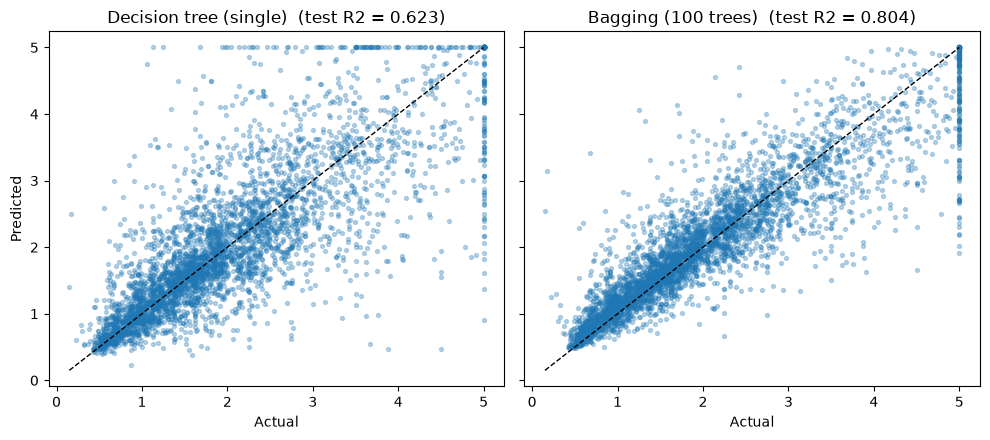

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), sharex=True, sharey=True)

for ax, (title, model) in zip(axes, [("Decision tree (single)", dt), ("Bagging (100 trees)", bag_100)]):
    ax.scatter(y_test, model.predict(X_test), alpha=0.3, s=8)
    lims = [y.min(), y.max()]
    ax.plot(lims, lims, "k--", linewidth=1)
    ax.set_title(f"{title}  (test R2 = {results[title]['test R2']:.3f})")
    ax.set_xlabel("Actual")
    
axes[0].set_ylabel("Predicted")
plt.tight_layout()
plt.show()

## 4. How many estimators?

More estimators never cause overfitting, but the gains flatten out quickly while the cost keeps growing linearly.
This plot shows where the test R² stops improving.

In [9]:
n_values = [1, 5, 10, 25, 50, 100, 200]
test_r2 = []

for n in n_values:
    model = BaggingRegressor(
        estimator=DecisionTreeRegressor(),
        n_estimators=n,
        n_jobs=-1,
        random_state=RANDOM_STATE,
    ).fit(X_train, y_train)
    test_r2.append(model.score(X_test, y_test))

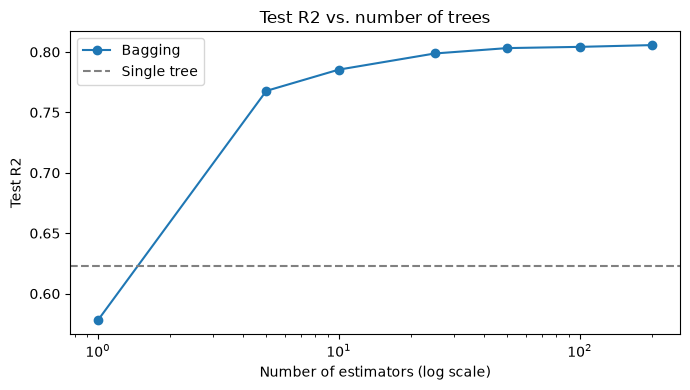

In [10]:
plt.figure(figsize=(7, 4))
plt.plot(n_values, test_r2, marker="o", label="Bagging")
plt.axhline(results["Decision tree (single)"]["test R2"], color="gray", linestyle="--", label="Single tree")
plt.xscale("log")
plt.xlabel("Number of estimators (log scale)")
plt.ylabel("Test R2")
plt.title("Test R2 vs. number of trees")
plt.legend()
plt.tight_layout()
plt.show()

## 5. Out-of-Bag (OOB) Score:

Each bootstrap sample leaves out roughly a third of the rows. Those *out-of-bag* rows act as a free validation set, so `oob_score_` (an R² for regression)
estimates generalisation performance **without a separate validation split**. It should land close to the test R².

In [11]:
bag_oob = evaluate(
    "Bagging + OOB (100 trees)",
    BaggingRegressor(
        estimator=DecisionTreeRegressor(),
        n_estimators=100,
        oob_score=True,
        n_jobs=-1,
        random_state=RANDOM_STATE,
    ),
)
print(f"OOB R2: {bag_oob.oob_score_:.3f}")

Bagging + OOB (100 trees): train R2 = 0.973 | test R2 = 0.804 | test RMSE = 0.51
OOB R2: 0.807


## 6. Hyperparameter Tuning with GridSearchCV:

The grid searches over the base estimator (decision tree or linear regression), the number of estimators, row and feature sampling, and whether each is drawn with replacement.

In [12]:
param_grid = {
    "estimator": [DecisionTreeRegressor(), LinearRegression()],
    "n_estimators": [20, 50, 100],
    "max_samples": [0.5, 1.0],
    "max_features": [0.5, 1.0],
    "bootstrap": [True, False],
    "bootstrap_features": [True, False],
}

In [13]:
search = GridSearchCV(
    BaggingRegressor(random_state=RANDOM_STATE),
    param_grid,
    cv=3,
    scoring="r2",
    n_jobs=-1,
    verbose=1,
)

In [14]:
start = time.perf_counter()
search.fit(X_train, y_train)
print(f"Grid search finished in {time.perf_counter() - start:.0f}s")

Fitting 3 folds for each of 96 candidates, totalling 288 fits
Grid search finished in 106s


In [15]:
print("Best params:", search.best_params_)
print(f"Best CV R2: {search.best_score_:.3f}")

Best params: {'bootstrap': False, 'bootstrap_features': True, 'estimator': DecisionTreeRegressor(), 'max_features': 1.0, 'max_samples': 1.0, 'n_estimators': 100}
Best CV R2: 0.802


The five best configurations, with the spread of their cross-validation scores:

In [16]:
pd.set_option("display.max_colwidth", None)
cv_results = pd.DataFrame(search.cv_results_)
cv_results.sort_values("rank_test_score").head(5)[["params", "mean_test_score", "std_test_score"]]

,params,mean_test_score,std_test_score
59,"{'bootstrap': False, 'bootstrap_features': True, 'estimator': DecisionTreeRegressor(), 'max_features': 1.0, 'max_samples': 1.0, 'n_estimators': 100}",0.801846,0.000651
35,"{'bootstrap': True, 'bootstrap_features': False, 'estimator': DecisionTreeRegressor(), 'max_features': 1.0, 'max_samples': 1.0, 'n_estimators': 100}",0.800353,0.000370
11,"{'bootstrap': True, 'bootstrap_features': True, 'estimator': DecisionTreeRegressor(), 'max_features': 1.0, 'max_samples': 1.0, 'n_estimators': 100}",0.798408,0.000738
34,"{'bootstrap': True, 'bootstrap_features': False, 'estimator': DecisionTreeRegressor(), 'max_features': 1.0, 'max_samples': 1.0, 'n_estimators': 50}",0.797833,0.000417
80,"{'bootstrap': False, 'bootstrap_features': False, 'estimator': DecisionTreeRegressor(), 'max_features': 1.0, 'max_samples': 0.5, 'n_estimators': 100}",0.797239,0.000690


The best configuration is refit on the full training set automatically (`refit=True` is the default), so it can be scored on the untouched test set directly.

In [17]:
best = evaluate("Bagging (GridSearchCV best)", search.best_estimator_, fit=False)

Bagging (GridSearchCV best): train R2 = 1.000 | test R2 = 0.804 | test RMSE = 0.51


## 7. Comparison:

All models on the same held-out test set. The gap between the train and test bars shows how much each model overfits.

                             train R2  test R2  test RMSE
Linear regression (single)      0.613    0.576      0.746
Decision tree (single)          1.000    0.623      0.703
KNN (single)                    0.797    0.670      0.658
Bagging (10 trees)              0.962    0.785      0.530
Bagging (100 trees)             0.973    0.804      0.507
Bagging + OOB (100 trees)       0.973    0.804      0.507
Bagging (GridSearchCV best)     1.000    0.804      0.506


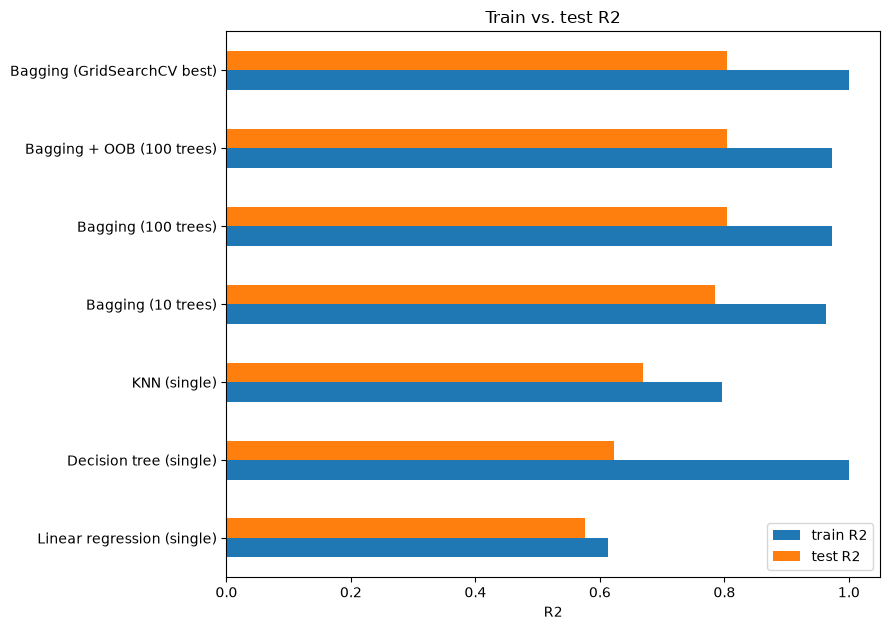

In [18]:
summary = pd.DataFrame(results).T.sort_values("test R2")
print(summary.round(3).to_string())

summary[["train R2", "test R2"]].plot.barh(figsize=(9, 0.7 * len(summary) + 1.5))
plt.xlabel("R2")
plt.title("Train vs. test R2")
plt.tight_layout()
plt.show()

## 8. Tips:

- Bagging mainly reduces **variance**, so it helps unstable, high-variance models (deep trees) far more than stable ones (linear regression).
- Averaging many trees keeps the low bias of a deep tree while smoothing out its noise. Compare the train/test gap of the single tree and the ensemble above.
- The OOB score is a free, nearly unbiased estimate of test performance, which is handy when data is scarce.
- Beyond a point, more estimators only cost time. Check the number-of-estimators plot before using hundreds.
- Distance-based base models such as KNN need scaled features, so wrap them in a `Pipeline` with a `StandardScaler` (as done for the KNN baseline). Trees and linear regression don't need it.